In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from CrocoDash.case import Case

In [2]:
# CESM case (experiment) name
casename = "ww3.obc.2"

# CESM source root (Update this path accordingly!!!)
cesmroot = Path("~/work/installs/full_regional_cesm").expanduser()

# Place where all your input files go
inputdir = Path.home() / "scratch" / "croc_input" / casename

# CESM case directory
caseroot = Path.home() / "croc_cases" / casename

# Same as the NYF alias, but SWAV -> WW3 (active wave model)
compset = "1850_DATM%NYF_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_WW3"

# 5-day window; configure_forcings/process_forcings derive STOP_N from this range
date_range = ["2020-01-01 00:00:00", "2020-01-31 00:00:00"]

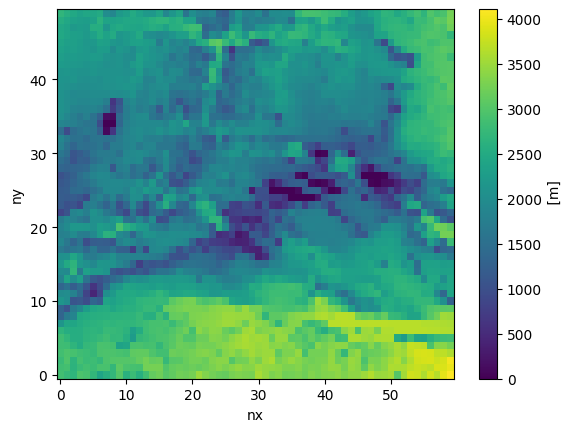

In [3]:
# Small flat-bathymetry grid, just enough to exercise case setup quickly
grid_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_hgrid_open_ocean_nar_10_4ea79c.nc"
bathymetry_path = "/glade/derecho/scratch/manishrv/croc_input/bd.oo.10thdegree/ocnice/ocean_topog_open_ocean_nar_10_4ea79c.nc"
grid = Grid.from_supergrid(grid_path)
topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.5,
)
topo.depth.plot()
vgrid  = VGrid.hyperbolic(
    nk = 75,
    depth = topo.max_depth,
    ratio=20.0
)

In [4]:

case = Case(
    cesmroot=cesmroot,
    caseroot=caseroot,
    inputdir=inputdir,
    compset=compset,
    ocn_grid=grid,
    ocn_topo=topo,
    ocn_vgrid=vgrid,
    atm_grid_name="T62",
    machine="derecho",
    project="ncgd0011",
    override=True,
)


INFO:	initialize:Initializing the visualCaseGen system...


INFO:  csp_solver:CspSolver initialized.


Creating case...

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/full_regional_cesm/cime/scripts/create_newcase --compset 1850_DATM%NYF_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_WW3 --res USER_RES --case /glade/u/home/manishrv/croc_cases/ww3.obc.2 --machine derecho --run-unsupported --project ncgd0011 --non-local 



The create_newcase command was successful.

Ocean grid directory /glade/u/home/manishrv/scratch/croc_input/ww3.obc.2/ocnice does not exist.


./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric --non-local



The following additional configuration options are required to run and must be provided with any listed arguments in configure_forcings:
  - WW3: boundaries
  - conditions: boundaries, product_name, function_name, compset


In [5]:
# reference_waves: fast, deterministic synthetic WW3 boundary spectra --
# no CDS API key / network access needed, unlike the real era5_wave_spectra
# default. Swap these two kwargs out (or drop them) to use real ERA5 data.
case.configure_forcings(
    date_range=date_range,
    ww3_obc_product_name="reference_waves",
    ww3_obc_function_name="get_reference_wave_spectra",
)

INFO:CrocoDash.forcing_configurations.base:[SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGC incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[REQUIRED] Activating WW3


INFO:CrocoDash.forcing_configurations.base:[SKIP] CICE incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIC incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIronForcing incompatible with compset


... (8 outputs left out)

INFO:CrocoDash.forcing_configurations.base:Configuring conditions


Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u

./xmlchange STOP_OPTION=ndays --non-local



./xmlchange STOP_N=30 --non-local



In [6]:
case.process_forcings(process_initial_condition=False, process_velocity_tracers = False)

INFO:CrocoDash.extract_forcings.obc:GET [south]: 2020-01-01 → 2020-01-31


INFO:CrocoDash.extract_forcings.obc:GET [north]: 2020-01-01 → 2020-01-31


INFO:CrocoDash.extract_forcings.obc:GET [west]: 2020-01-01 → 2020-01-31


INFO:CrocoDash.extract_forcings.obc:GET [east]: 2020-01-01 → 2020-01-31


INFO:CrocoDash.extract_forcings.obc:REGRID [south]: None-day slices


INFO:CrocoDash.extract_forcings.obc:Saved regridded file as forcing_obc_segment_001_2020-01-01_2020-01-31.nc


... (12 outputs left out)

INFO:CrocoDash.extract_forcings.obc:MERGE [east]


INFO:CrocoDash.extract_forcings.obc:Saved merged boundary at /glade/u/home/manishrv/scratch/croc_input/ww3.obc.2/extract_forcings/ww3/merged/forcing_obc_segment_004.nc


INFO:CrocoDash.extract_forcings.obc:OBC processing complete.


[timing] ww3: 1.6s  total: 1.6s
Case is ready to be built: /glade/u/home/manishrv/croc_cases/ww3.obc.2


In [7]:
import xarray as xr

wave_dir = inputdir / "wave"
spec_names = (wave_dir / "spec.list").read_text().splitlines()
print("total synthetic stations across all boundaries:", len(spec_names))

ds = xr.open_dataset(wave_dir / spec_names[0], decode_times=False)
print("dims:", dict(ds.sizes))
print("efth range:", float(ds["efth"].min()), "-", float(ds["efth"].max()))

total synthetic stations across all boundaries: 12
dims: {'time': 124, 'frequency': 12, 'direction': 16, 'latitude': 1, 'longitude': 1}
efth range: 0.0 - 11.061468124389648
